## Spinup Validation
Check spinup results to see if they make sense. Test algorithms for automatic validation.

In [1]:
# Alpine - export environmental variables since they don't appear to load
import os
os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output'
os.environ['SNOTEL_PATH'] = r'/pl/active/snotelmodelling/snotel/'
os.environ['FORCING_PATH'] = r'/pl/active/snotelmodelling/model_data/input/forcing/'

In [2]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 

Load datasets

In [3]:
site = 'truckee2'
run_id = '0004'

In [4]:
forcing = LM4Forcing(
    site=site,
    forcing_string='00000000',
    version='0.9.1',
    spinup=True
)

spinup = LM4ModelOutput(site=site, forcing_string='00000000', namelist='gbc', version=run_id, spinup=True)

In [5]:
daily_vars = spinup.get_variables(diag='land_daily')

In [6]:
daily_vars

,dimensions,long_name,units
fco2,"(time, grid_index)",flux of CO2 to canopy air,kg C/(m2 s)
t_ref,"(time, grid_index)",temperature at 2 m over land,deg_k
co2_mol_flux,"(time, grid_index)",flux of carbon dioxide,mol CO2/(m2 s)
co2_mol_flux1,"(time, grid_index)",flux of CO2 to the atmosphere,mol/(m2 s)
btot,"(time, grid_index)",total biomass,kg C/m2
Ctot,"(time, grid_index)",total land carbon,kg C/m2
ncohorts,"(time, grid_index)",number of cohorts,unitless
nindivs,"(time, grid_index)",density of individuals,individuals/m2
nlayers,"(time, grid_index)",number of canopy layers,unitless
ntiles,"(time, grid_index)",number of tiles,unitless


In [7]:
monthly_vars = spinup.get_variables(diag='land_month')

In [8]:
len(monthly_vars)

152

In [9]:
monthly_vars.iloc[75:120].head(50)

,dimensions,long_name,units
dbh,"(time, grid_index)",diameter at breast height,m
crownarea,"(time, grid_index)",mean area of individuals crown,m2
gdd,"(time, grid_index)",growing degree days,degK day
tc_pheno,"(time, grid_index)",smoothed canopy air temperature for phenology,degK
status,"(time, grid_index)",status of leaves,
bl_max,"(time, grid_index)",max biomass of leaves,kg C/m2
br_max,"(time, grid_index)",max biomass of fine roots,kg C/m2
con_v_v,"(time, grid_index)",conductance for water vapor between canopy and...,m/s
con_v_h,"(time, grid_index)",conductance for sensible heat between canopy a...,m/s
con_g_v,"(time, grid_index)",conductance for water vapor between ground sur...,m/s


### Vegetation

In [10]:
spinup_veg = spinup.get_data(['height_ave','lai'], diag='land_month')

/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/model_datasets/output.py:80: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex instead of a 'ns'-resolution DatetimeIndex. This warning can be silenced by explicitly passing the `time_unit` keyword argument.
  return land_month['time'].to_index().to_datetimeindex()
/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/model_datasets/output.py:80: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  return land_month['time'].to_index().to_datetimeindex()


Text(0, 0.5, 'LAI (m^2/m^2)')

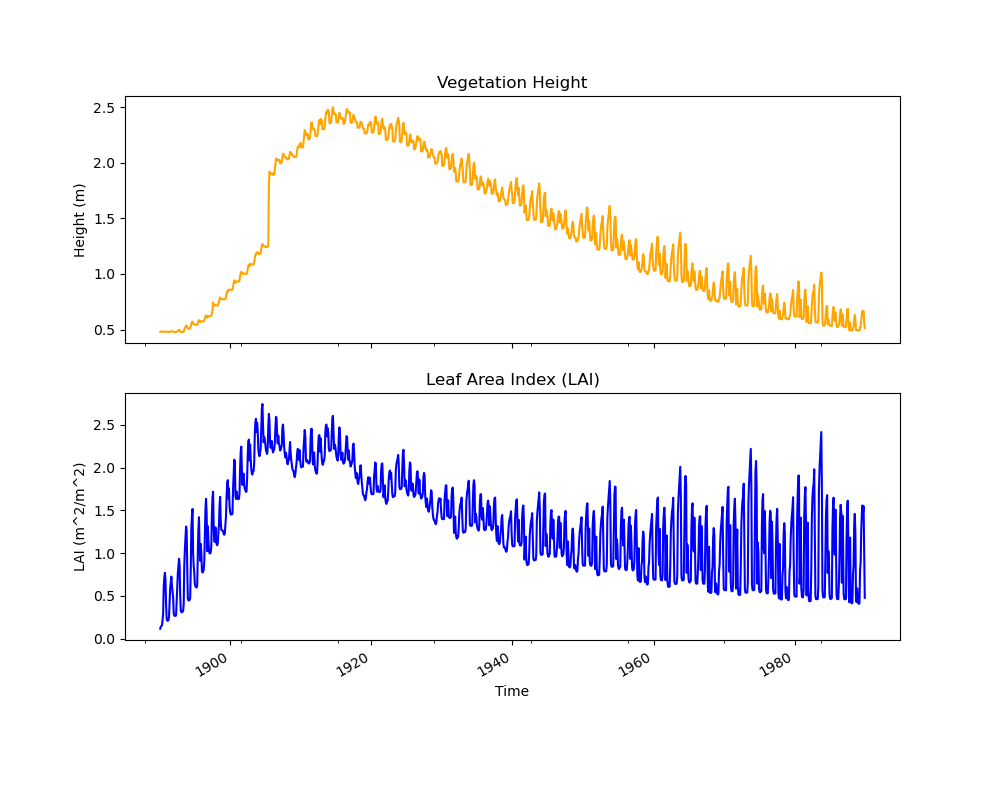

In [11]:
# Plot vegetation height and LAI for both models
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
spinup_veg['height_ave'].plot(ax=ax[0], label='CM Height', color='orange')
spinup_veg['lai'].plot(ax=ax[1], label='CM LAI', color='blue')
ax[0].set_title('Vegetation Height')
ax[1].set_title('Leaf Area Index (LAI)')
ax[1].set_xlabel('Time')
ax[0].set_ylabel('Height (m)')
ax[1].set_ylabel('LAI (m^2/m^2)')

### Snow

For many variables, I only care about the last 10 years of the spinup, so I will slice the data accordingly.

In [12]:
spinup_snow = spinup.get_data(['snow','snow_depth','t_ref'],'land_daily')

In [13]:
forcing.get_variables()

,dimensions,long_name,units
Tair,"(time, latitude, longitude)",Near-surface air Temperature,K
Qair,"(time, latitude, longitude)",Near-surface specific humidity,kg/kg
Psurf,"(time, latitude, longitude)",Surface Pressure,Pa
Rainf,"(time, latitude, longitude)",Rainfall rate,kg/m2/s
Snowf,"(time, latitude, longitude)",Snowfall rate,kg/m2/s
SWdown,"(time, latitude, longitude)",Surface downward shortwave radiation,W/m2
LWdown,"(time, latitude, longitude)",Surface downward longwave radiation,W/m2
Wind,"(time, latitude, longitude)",Near-surface wind speed,m/s
reference_height,"(latitude, longitude)",,
canopy_height,"(latitude, longitude)",,


In [14]:
Tair = forcing.get_looped_data('Tair', 100)
Tair = Tair - 273.15  # Convert Tair to Celsius

In [15]:
Tair.tail()

1990-01-02 12:00:00    3.380833
1990-01-03 12:00:00   -0.998750
1990-01-04 12:00:00   -2.204167
1990-01-05 12:00:00    0.939167
1990-01-06 12:00:00    2.057500
Freq: D, Name: Tair, dtype: float64

In [16]:
# Calculate total daily snow precipitation
Snowf = forcing.get_data('Snowf')
Snowf_daily = Snowf.resample('1D').sum()
forcing_snow = Snowf_daily * 24 * 3600  # Convert from kg/m^2/s to kg/m^2/day

In [17]:
# Get the starting and ending years for the last 10 years of the spinup
end_date = spinup_snow['snow_depth'].index[-1]
start_date = spinup_snow['snow_depth'].index[-1] - pd.DateOffset(years=10)

print(f'{start_date}:{end_date}')

1980-01-01 12:00:00:1990-01-01 12:00:00


<Axes: >

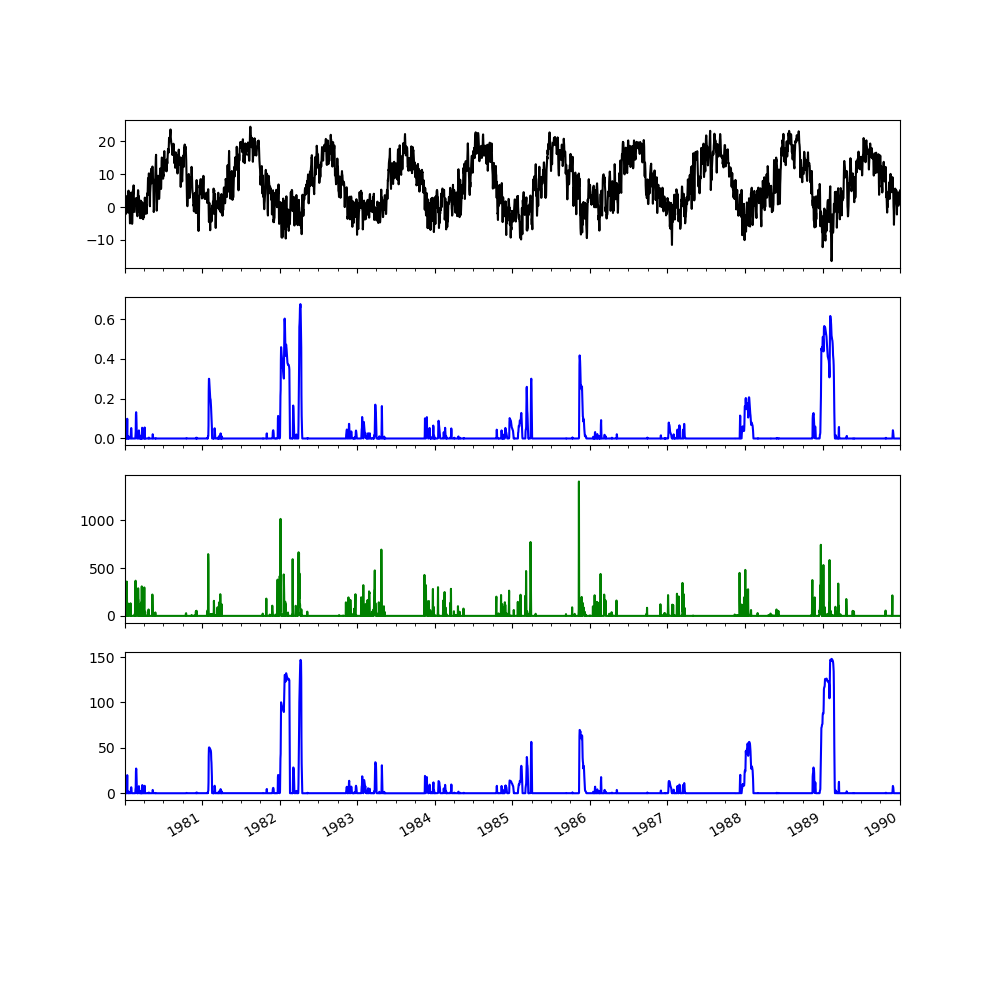

In [18]:
# Plot forcing temperatures and snow depths
fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
Tair[start_date:end_date].plot(ax=ax[0], label='Tair', color='black')
#spinup_snow.loc[start_date:end_date, 't_ref'].plot(ax=ax[0], label='CM t_ref', color='blue')
spinup_snow.loc[start_date:end_date, 'snow_depth'].plot(ax=ax[1], label='CM Snow Depth', color='blue')
forcing_snow[start_date:end_date].plot(ax=ax[2], label='Snow Precipitation', color='green')
spinup_snow.loc[start_date:end_date, 'snow'].plot(ax=ax[3], label='CM Snow', color='blue')


### Soil Temperature

In [19]:
spinup_soil = spinup.get_data(['soil_T'], diag='land_daily')

In [20]:
# Change data in soil dataframes to celsius
spinup_soil = spinup_soil - 273.15

<Axes: >

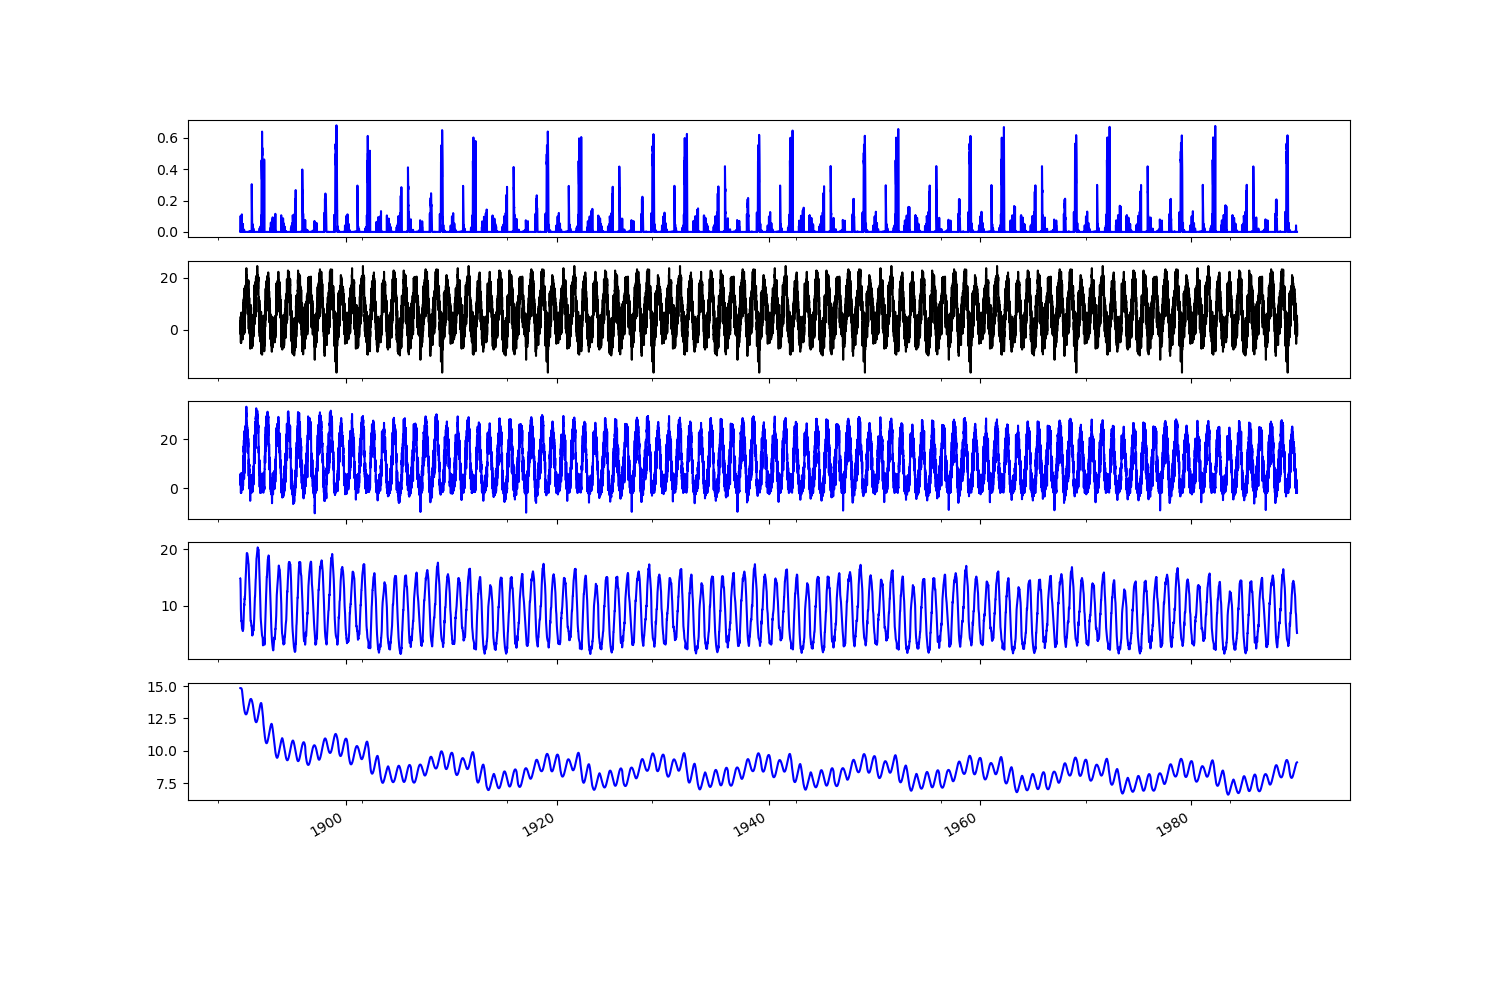

In [21]:
# Plot snow, Tair, and soil temperatures at 0.04, 1.20, 5.50m
fig, ax = plt.subplots(5, 1, figsize=(15, 10), sharex=True)
spinup_snow['snow_depth'].plot(ax=ax[0], label='CM Snow Depth', color='blue')
Tair.plot(ax=ax[1], label='Tair', color='black')
spinup_soil['soil_T 0.04'].plot(ax=ax[2], label='CM Soil T 0.04m', color='blue')
spinup_soil['soil_T 1.20'].plot(ax=ax[3], label='CM Soil T 1.20m', color='blue')
spinup_soil['soil_T 5.50'].plot(ax=ax[4], label='CM Soil T 5.50m', color='blue')

#### Soil liquid/ice water content
These variables are currently in monthly data.

In [22]:
spinup_soil_water = spinup.get_data(['soil_liq'], diag='land_month')

/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/model_datasets/output.py:80: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex instead of a 'ns'-resolution DatetimeIndex. This warning can be silenced by explicitly passing the `time_unit` keyword argument.
  return land_month['time'].to_index().to_datetimeindex()
/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/model_datasets/output.py:80: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  return land_month['time'].to_index().to_datetimeindex()


In [23]:
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

<Axes: >

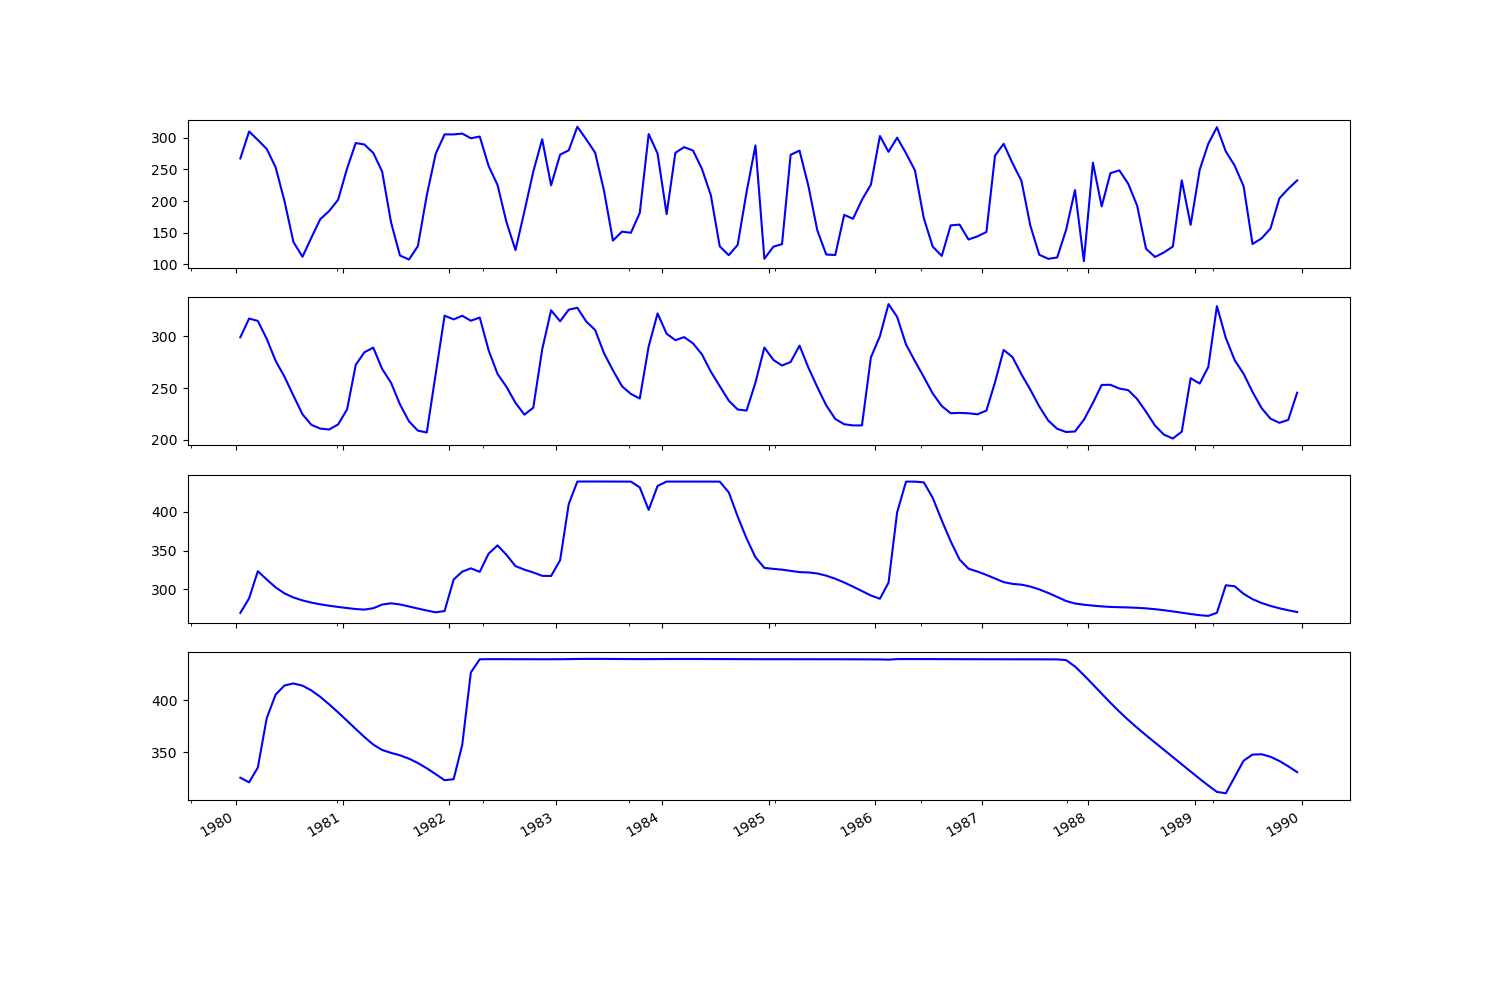

In [24]:
# Plot soil water content for both models at depths 0.04, 1.20, 5.50 and 8.75m
fig, ax = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
spinup_soil_water.loc[start_date:end_date, 'soil_liq 0.04'].plot(ax=ax[0], label='CM Soil Liq 0.04m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 1.20'].plot(ax=ax[1], label='CM Soil Liq 1.20m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 5.50'].plot(ax=ax[2], label='CM Soil Liq 5.50m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 8.75'].plot(ax=ax[3], label='CM Soil Liq 8.75m', color='blue')